# 01 · EEG fundamentals and data provenance

## Goal
Understand voltage references, samples, channels, annotations, and the distinction between a recording, a run, a trial, and a participant.

**Scope:** a reproducible teaching analysis of public recordings, not clinical validation. Downloaded data are cached locally; no synthetic fallback is used. Each notebook runs independently.

## Setup
Use the environment in `README.md`. The default sample is deliberately small; results are descriptive unless explicitly stated otherwise.

In [1]:
from pathlib import Path
import sys
course_dir = Path.cwd() if (Path.cwd() / 'course_utils.py').exists() else Path.cwd() / 'EEG_from_ground_up'
assert (course_dir / 'course_utils.py').exists(), 'Open this notebook from the course folder or project root.'
sys.path.insert(0, str(course_dir.resolve()))
from course_utils import ROOT, DATA, OUTPUT, SEED, load_run, versions, style, save_table
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne
from IPython.display import display
%matplotlib inline
style()
rng = np.random.default_rng(SEED)
display(versions().to_frame())

,version
numpy,2.5.4
scipy,1.18.1
pandas,3.0.6
matplotlib,3.11.2
mne,1.13.2
moabb,1.7.2
pyriemann,0.12
braindecode,1.8.1
torch,2.14.1
scikit-learn,1.9.1


## Steps

### 1. The measurement model
For C channels and T samples, X has shape C × T. A scalp channel measures a voltage difference, not the activity of one isolated brain region. A conceptual model is X = AS + E, where A mixes neural sources and E contains artifacts and noise. Source recovery is not unique.

PhysioNet uses 64 channels at 160 Hz. Runs 1/2 are eyes open/closed; runs 4/8/12 are left/right **imagery**. Runs 3/7/11 are actual movement. T1/T2 mean something different in the hands/feet runs: never interpret labels without the run protocol.
**Objects used throughout the course:** `Raw` stores continuous channels × samples plus annotations; `Epochs` stores trials × channels × samples plus metadata; `Evoked` stores an average over selected epochs. Preserve the unaveraged trials whenever uncertainty or decoding matters.

At sampling rate $f_s$, sample $n$ corresponds to $t_n=n/f_s$. The Nyquist frequency is $f_s/2$. A file’s length in samples divided by $f_s$ is its nominal duration; its last sample occurs one sample interval earlier. Electrode coordinates describe sensor positions, not an inverse solution for brain sources.

In [3]:
SUBJECT, RUN = 1, 4
raw = load_run(SUBJECT, RUN)
display(pd.DataFrame([{'subject':SUBJECT,'run':RUN,'channels':len(raw.ch_names),
    'samples':raw.n_times,'sample_rate_Hz':raw.info['sfreq'],
    'recording_length_s':raw.n_times/raw.info['sfreq'],'Nyquist_Hz':raw.info['sfreq']/2}]))
display(pd.DataFrame({'channel':raw.ch_names,'type':raw.get_channel_types()}).head(12))

/Users/trush/Documents/Research/Synaptrix/synaptrixmotorimagerydata/EEG_from_ground_up/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,subject,run,channels,samples,sample_rate_Hz,recording_length_s,Nyquist_Hz
0,1,4,64,20000,160.0,125.0,80.0


,channel,type
0,FC5,eeg
1,FC3,eeg
2,FC1,eeg
3,FCz,eeg
4,FC2,eeg
5,FC4,eeg
6,FC6,eeg
7,C5,eeg
8,C3,eeg
9,C1,eeg


### 2. Read traces in physical units
MNE represents EEG in volts. Multiply by 10⁶ only for a microvolt plot. Offsets below are for readability, not a reference change. Large excursions are observations requiring inspection, not automatically neural events.

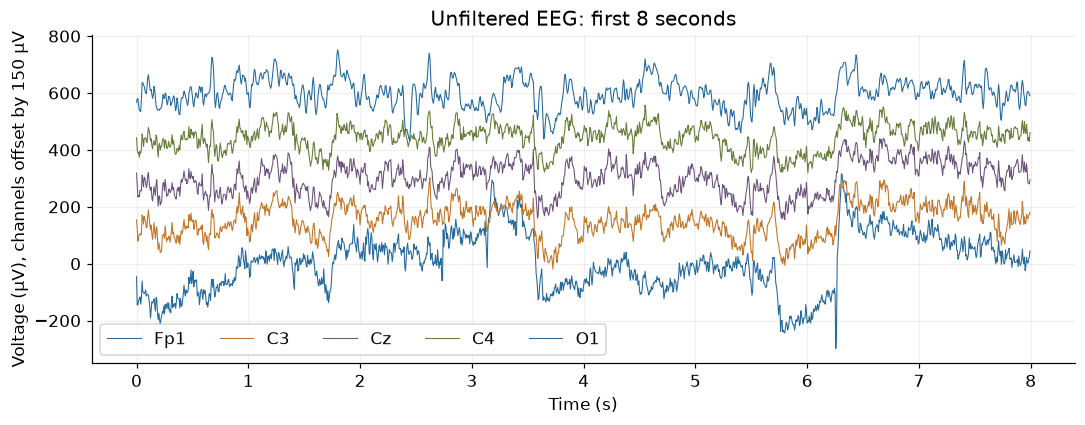

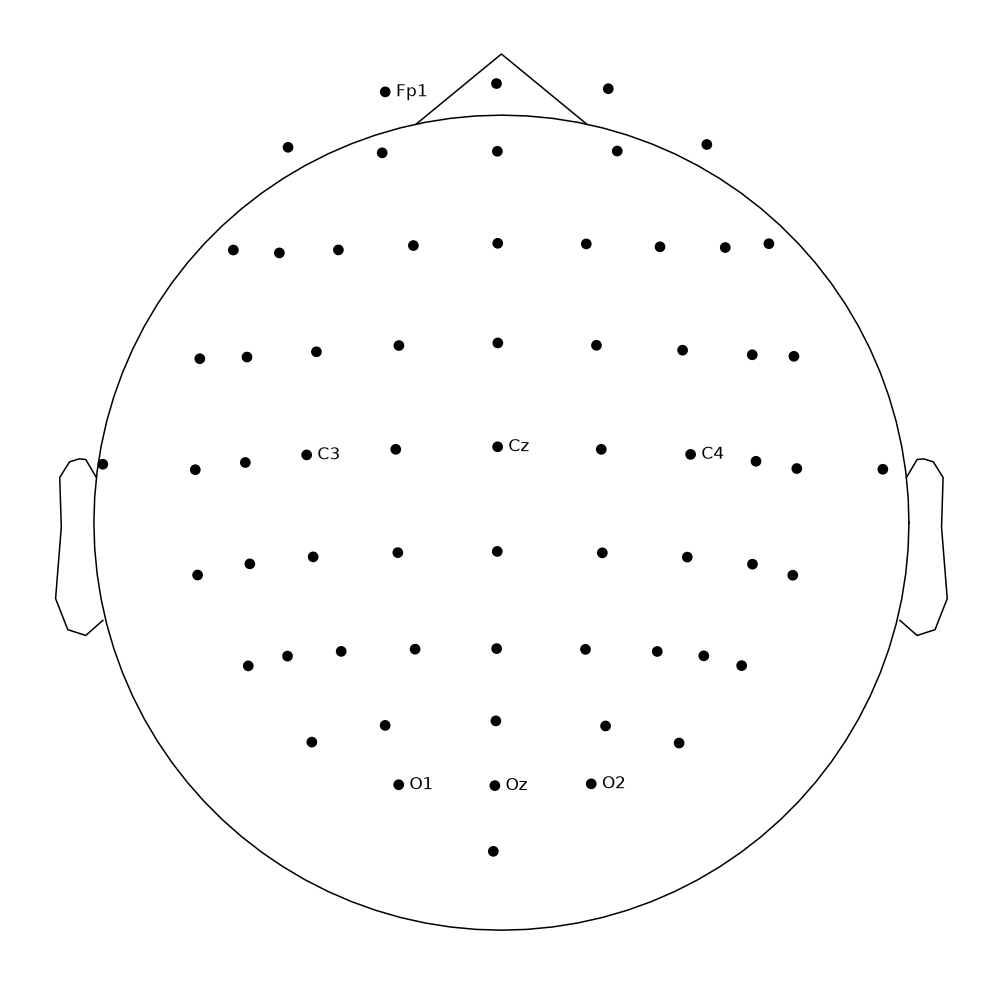

In [5]:
picks=['Fp1','C3','Cz','C4','O1']
x=raw.get_data(picks=picks, start=0, stop=int(8*raw.info['sfreq']))*1e6
t=np.arange(x.shape[1])/raw.info['sfreq']
fig,ax=plt.subplots(figsize=(10,4))
for k,ch in enumerate(picks): ax.plot(t,x[k]+k*150,lw=.7,label=ch)
ax.set(xlabel='Time (s)',ylabel='Voltage (µV), channels offset by 150 µV',title='Unfiltered EEG: first 8 seconds')
ax.legend(ncol=5); plt.tight_layout(); plt.show()
raw.plot_sensors(show_names=['Fp1','C3','Cz','C4','O1','Oz','O2'], show=False); plt.show()

### 3. Events and labels
An annotation onset is not necessarily the onset of the participant’s internal intention. Here it is the experimental task marker. Preserve these timestamps and the recording identity.

In [7]:
annotations=pd.DataFrame({'onset_s':raw.annotations.onset,'duration_s':raw.annotations.duration,
    'annotation':raw.annotations.description})
display(annotations.head(12))
events,event_id=mne.events_from_annotations(raw,event_id={'T1':1,'T2':2},verbose=False)
trial_table=pd.DataFrame({'subject':SUBJECT,'run':RUN,'sample':events[:,0],
    'onset_s':events[:,0]/raw.info['sfreq'],'label':np.where(events[:,2]==1,'left_hand','right_hand')})
display(save_table(trial_table,'01_trial_inventory.csv'))

,onset_s,duration_s,annotation
0,0.0,4.2,T0
1,4.2,4.1,T2
2,8.3,4.2,T0
3,12.5,4.1,T1
4,16.6,4.2,T0
5,20.8,4.1,T1
6,24.9,4.2,T0
7,29.1,4.1,T2
8,33.2,4.2,T0
9,37.4,4.1,T2


,subject,run,sample,onset_s,label
0,1,4,672,4.2,right_hand
1,1,4,2000,12.5,left_hand
2,1,4,3328,20.8,left_hand
3,1,4,4656,29.1,right_hand
4,1,4,5984,37.4,right_hand
5,1,4,7312,45.7,left_hand
6,1,4,8640,54.0,right_hand
7,1,4,9968,62.3,left_hand
8,1,4,11296,70.6,right_hand
9,1,4,12624,78.9,left_hand


### 4. Referencing is a linear transformation
Average reference is $x'_i(t)=x_i(t)−C^{-1}\Sigma_j x_j(t)$. It removes one spatial degree of freedom. It does not reconstruct the original acquisition reference, which this notebook does not independently establish. Bad channels should be addressed before estimating a common average.

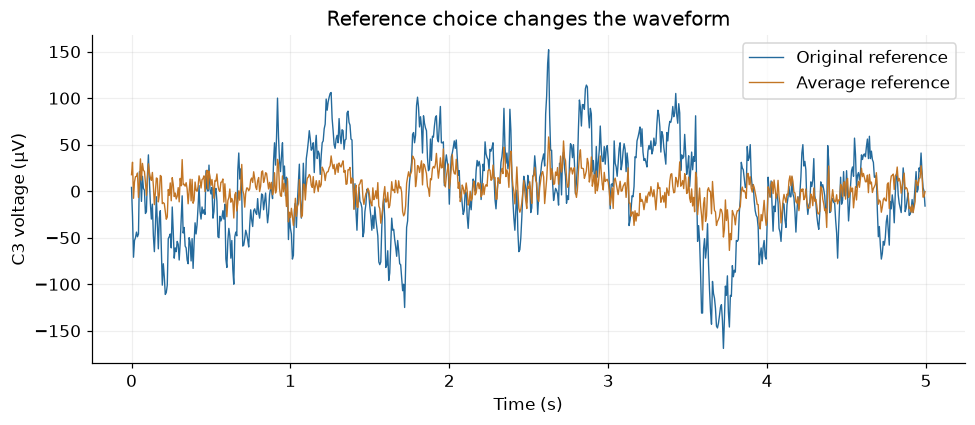

In [11]:
ref=raw.copy().set_eeg_reference('average',projection=False,verbose=False)
assert np.max(np.abs(ref.get_data().mean(axis=0))) < 1e-12
fig,ax=plt.subplots()
for r,label in [(raw,'Original reference'),(ref,'Average reference')]:
    ax.plot(r.times[:800],r.get_data(picks=['C3'])[0,:800]*1e6,label=label,lw=.9)
ax.set(xlabel='Time (s)',ylabel='C3 voltage (µV)',title='Reference choice changes the waveform')
ax.legend(); plt.tight_layout(); plt.show()

## Checks
Sample spacing must equal 1/fs; all values must be finite. The manifest records the exact source URL and local SHA-256 for each EDF. These hashes identify your local files; they are not a substitute for an upstream signature.

In [13]:
assert np.isfinite(raw.get_data()).all()
assert np.allclose(np.diff(raw.times),1/raw.info['sfreq'])
assert set(events[:,2])=={1,2}
print('Checks passed. Trial counts:',trial_table.label.value_counts().to_dict())

Checks passed. Trial counts: {'left_hand': 8, 'right_hand': 7}


## Next Steps
In Notebook 02, ask whether eyes-open and eyes-closed recordings differ spectrally.

**Exercises:** (1) Calculate the sample index at 2.5 s. (2) Explain why a 160 Hz recording cannot resolve a 100 Hz oscillation unambiguously. (3) Explain why 64 channels need not contain 64 independent signals.

**Answer checks:** 400 samples from the start; Nyquist is 80 Hz; volume conduction, shared reference, and re-referencing create dependence.

## Sources and further reading
Original teaching code; the resources below provide APIs, methodological guidance, and dataset provenance. No tutorial text or full external notebook is reproduced.

- [PhysioNet dataset and protocol](https://physionet.org/content/eegmmidb/1.0.0/)
- [MNE tutorials](https://mne.tools/stable/auto_tutorials/index.html)
- [OpenNeuro and BIDS metadata](https://docs.openneuro.org/user_guide.html)